# 02 · Comparing imputation methods

**Goal:** choose how to fill readings removed as sensor faults.

**Method:** take the valid readings of one pond, hide a random 10 % of the observed cells of each sensor (fixed seed), fill them with each method and score **only the hidden cells** against their true values. Every method sees the same input columns. Errors are reported per variable, and as NRMSE (RMSE divided by the variable's standard deviation) so variables on different scales can be compared.

In [1]:
import os, sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import importlib
import src.pond_pipeline
importlib.reload(src.pond_pipeline)  # pick up edits to src/ even if this kernel imported it earlier
from src.pond_pipeline import *  # noqa: F401,F403  (column names, thresholds, helpers)

# Raw pond CSVs live in data/raw/ (see data/README.md). Override with POND_RAW_DIR if needed.
RAW = Path(os.environ.get("POND_RAW_DIR", RAW_DIR))
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer, SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures

POND = int(os.environ.get("POND", 6))
files = {pond_number(f): f for f in RAW.glob("*.csv")}
pond_file = files.get(POND) or next(iter(files.values()))
data = remove_invalid(load_pond(pond_file))[MODEL_SENSOR_COLS]
print(pond_file.name, data.shape)
data.isna().mean()

Iotpond6.csv (91015, 4)


Temperature (C)           0.000000
Dissolved Oxygen(mg/L)    0.129023
PH                        0.321431
Nitrate(mg/L)             0.000824
dtype: float64

In [3]:
rng = np.random.default_rng(RANDOM_STATE)
masked = data.copy()
hidden = {}
for col in MODEL_SENSOR_COLS:
    observed = data.index[data[col].notna()]
    idx = rng.choice(observed, size=int(0.10 * len(observed)), replace=False)
    masked.loc[idx, col] = np.nan
    hidden[col] = idx

In [4]:
def impute_mean(df):
    return pd.DataFrame(SimpleImputer().fit_transform(df), index=df.index, columns=df.columns)

def impute_knn(df):
    return knn_impute_scaled(df, list(df.columns))

def impute_iterative(df):
    imp = IterativeImputer(random_state=RANDOM_STATE, max_iter=100, tol=1e-3)
    return pd.DataFrame(imp.fit_transform(df), index=df.index, columns=df.columns)

def impute_polynomial(df):
    # same function the cleaning in notebook 03 uses; clip=False so the raw prediction is scored
    return polynomial_impute(df, list(df.columns), clip=False)

methods = {"Mean": impute_mean, "KNN (k=5, scaled)": impute_knn,
           "Iterative": impute_iterative, "Polynomial regression": impute_polynomial}

In [5]:
rows = []
for name, fn in methods.items():
    filled = fn(masked)
    for col in MODEL_SENSOR_COLS:
        idx = hidden[col]
        err = filled.loc[idx, col] - data.loc[idx, col]
        rmse = float(np.sqrt(np.mean(err ** 2)))
        rows.append({"method": name, "variable": col, "RMSE": rmse,
                     "MAE": float(np.mean(np.abs(err))), "NRMSE": rmse / data[col].std()})
scores = pd.DataFrame(rows)
summary = scores.pivot(index="method", columns="variable", values="NRMSE")
summary["mean NRMSE"] = summary.mean(axis=1)
summary = summary.sort_values("mean NRMSE")
summary.to_csv(RESULTS_DIR / "imputation_comparison.csv")
summary

variable,Dissolved Oxygen(mg/L),Nitrate(mg/L),PH,Temperature (C),mean NRMSE
method,,,,,
Polynomial regression,0.934861,0.747110,0.643253,0.751284,0.769127
Iterative,0.976188,0.678746,0.707203,0.902837,0.816244
"KNN (k=5, scaled)",1.097436,1.054019,0.958340,0.853382,0.990794
Mean,0.997387,1.000187,0.987308,0.993285,0.994542


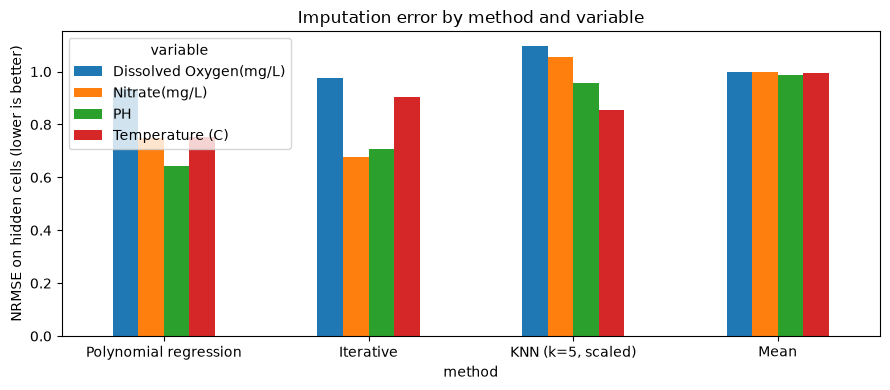

In [6]:
summary.drop(columns="mean NRMSE").plot.bar(figsize=(9, 4), rot=0)
plt.ylabel("NRMSE on hidden cells (lower is better)")
plt.title("Imputation error by method and variable")
plt.tight_layout()
plt.show()

The method with the lowest mean NRMSE is used in notebook 03. On the full data (pond 6) this was **polynomial regression** (mean NRMSE 0.743), ahead of iterative imputation (0.789), KNN (0.975) and the mean (1.000). The thesis used KNN; its earlier comparison scored the two methods on different cells. To use KNN instead, call `clean_pond(..., method="knn")` in notebook 03.